# CNN 1D multicanale
Baseline convoluzionale sui segnali raw (tre assi). Normalizzazione per asse stimata esclusivamente sul training fold; il pooling ignora i campioni padding usando `n_samples`. Early stopping sulla validation interna al training fold. Dipendenza: PyTorch.

In [1]:
import config as cfg, utils, advanced_models as adv
utils.print_versions()
adv.print_versions()
utils.print_config()
print('batch_size/epochs:', cfg.QUICK_TORCH_BATCH_SIZE, cfg.QUICK_TORCH_MAX_EPOCHS) if cfg.QUICK_TEST else print(cfg.TORCH_BATCH_SIZE, cfg.TORCH_MAX_EPOCHS)
MODEL = 'cnn1d'

Python      : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
sklearn     : 1.9.1
catboost    : 1.2.10
matplotlib  : 3.11.2
natsort     : 8.4.0
tqdm        : 4.70.1
Python: 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
xgboost: 3.4.1
sktime: 1.2.0
torch: 2.14.1
SEED=89  N_SPLITS=10  CV_MODE=stratified  QUICK_TEST=False
FALL_CLASSES: {'UniMiB': [9, 10, 11, 12, 13, 14, 15, 16], 'UniZgFall': [5, 6, 7]}
64 30


## Cross-validation, metriche e predizioni

In [2]:
adv.run_all(MODEL)

[cnn1d | UniZgFall | raw] X=(468, 3, 5150), classi=10, CV=stratified, fold=10
Parametri: max_epochs=30, batch_size=64, lr=0.001, weight_decay=0.0001


cnn1d|UniZgFall:   0%|          | 0/10 [00:00<?, ?it/s]

[cnn1d | UniZgFall | raw | fold 1/10] train su 421 esempi, test su 47
fit in corso...


/home/agrume/Desktop/projects/thesis/fall_detection_ml/advanced_models.py:296: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y_tensor = torch.from_numpy(np.asarray(y, dtype=np.int64))


  epoch 1/30: train_loss=3.9567, val_loss=2.0565, val_acc=0.3529
  epoch 2/30: train_loss=1.5282, val_loss=1.6768, val_acc=0.4471
  epoch 3/30: train_loss=1.1848, val_loss=1.4636, val_acc=0.5765
  epoch 4/30: train_loss=0.9351, val_loss=1.2033, val_acc=0.6706
  epoch 5/30: train_loss=0.7970, val_loss=0.9537, val_acc=0.7412
  epoch 6/30: train_loss=0.6944, val_loss=0.7966, val_acc=0.7765
  epoch 7/30: train_loss=0.5517, val_loss=0.6842, val_acc=0.8235
  epoch 8/30: train_loss=0.4787, val_loss=0.6225, val_acc=0.8353
  epoch 9/30: train_loss=0.3960, val_loss=0.5649, val_acc=0.8235
  epoch 10/30: train_loss=0.3239, val_loss=0.5780, val_acc=0.7882
  epoch 11/30: train_loss=0.2689, val_loss=0.4930, val_acc=0.8941
  epoch 12/30: train_loss=0.2445, val_loss=0.4558, val_acc=0.8941
  epoch 13/30: train_loss=0.2164, val_loss=0.4237, val_acc=0.9294
  epoch 14/30: train_loss=0.1941, val_loss=0.4022, val_acc=0.9294
  epoch 15/30: train_loss=0.1687, val_loss=0.4177, val_acc=0.9059
  epoch 16/30: trai

cnn1d|UniMiB:   0%|          | 0/10 [00:00<?, ?it/s]

[cnn1d | UniMiB | raw | fold 1/10] train su 1782 esempi, test su 198
fit in corso...
  epoch 1/30: train_loss=2.9448, val_loss=2.3860, val_acc=0.2493
  epoch 2/30: train_loss=2.0346, val_loss=1.8605, val_acc=0.3978
  epoch 3/30: train_loss=1.6510, val_loss=1.7014, val_acc=0.4006
  epoch 4/30: train_loss=1.4392, val_loss=1.5533, val_acc=0.4678
  epoch 5/30: train_loss=1.3195, val_loss=1.4620, val_acc=0.5350
  epoch 6/30: train_loss=1.0624, val_loss=1.2649, val_acc=0.5686
  epoch 7/30: train_loss=0.8775, val_loss=1.2495, val_acc=0.5770
  epoch 8/30: train_loss=0.6997, val_loss=1.2305, val_acc=0.6190
  epoch 9/30: train_loss=0.6179, val_loss=1.1769, val_acc=0.5406
  epoch 10/30: train_loss=0.5009, val_loss=1.2187, val_acc=0.6050
  epoch 11/30: train_loss=0.4090, val_loss=1.1328, val_acc=0.6162
  epoch 12/30: train_loss=0.3581, val_loss=1.1810, val_acc=0.5854
  epoch 13/30: train_loss=0.2936, val_loss=1.1732, val_acc=0.6331
  epoch 14/30: train_loss=0.2361, val_loss=1.0859, val_acc=0.6275


## Riepilogo

In [3]:
display(adv.summary_table(MODEL))

,dataset,input,accuracy,f1_macro,precision_macro,recall_macro,fit_time,predict_time,fall_sensitivity,fall_specificity,fall_precision
0,UniZgFall,raw,0.8951 ± 0.0606,0.8689 ± 0.1109,0.8903 ± 0.1068,0.8693 ± 0.1087,6.8921 ± 1.6764,0.0129 ± 0.0003,0.9027 ± 0.0880,0.9863 ± 0.0192,0.9511 ± 0.0655
1,UniMiB,raw,0.6672 ± 0.0597,0.6830 ± 0.0629,0.7153 ± 0.0487,0.6918 ± 0.0586,16.4237 ± 3.5173,0.0373 ± 0.0038,0.9854 ± 0.0162,0.9833 ± 0.0184,0.9938 ± 0.0068


## Grafici, incluse le curve di training/validazione

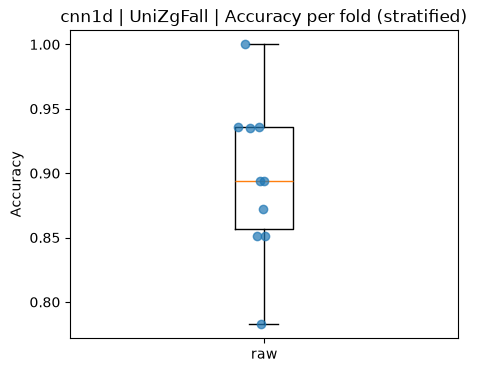

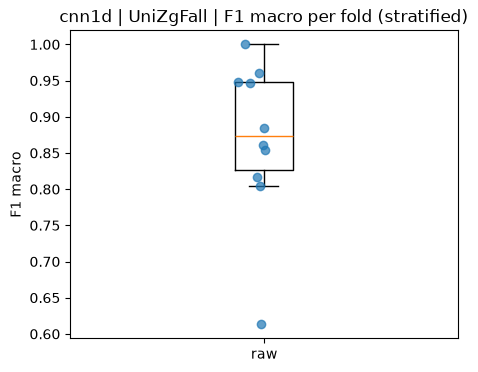

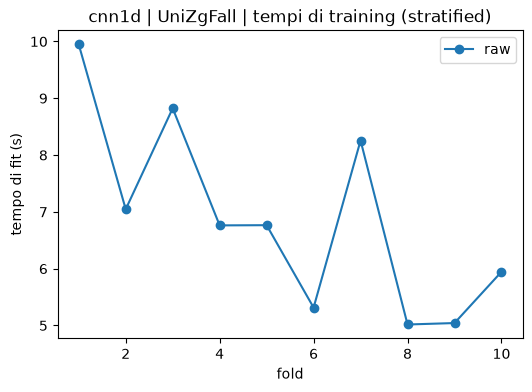

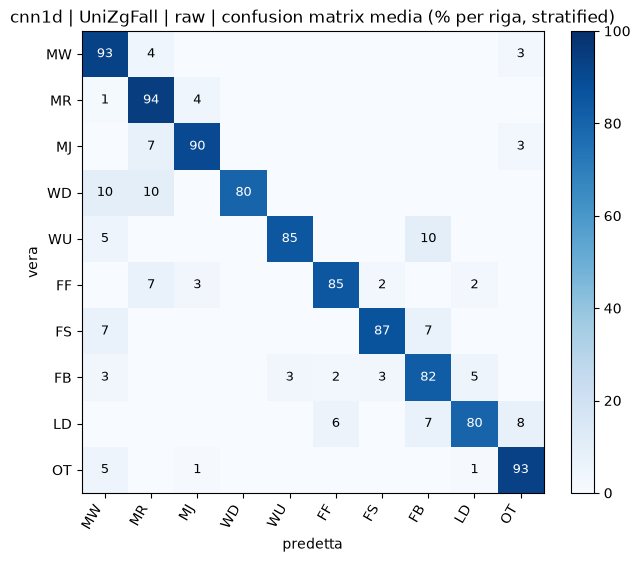

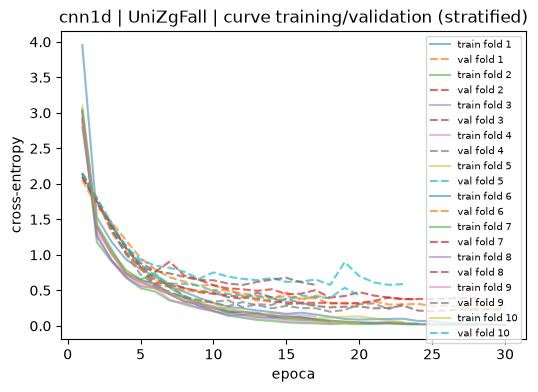

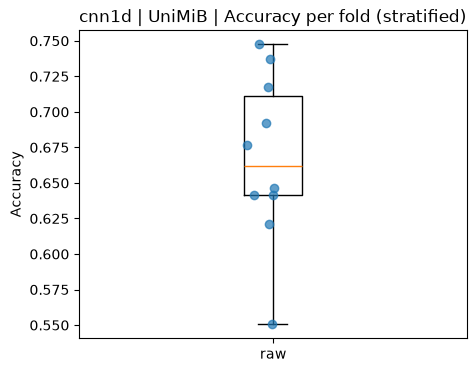

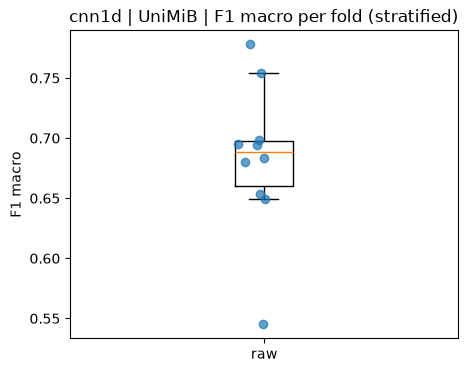

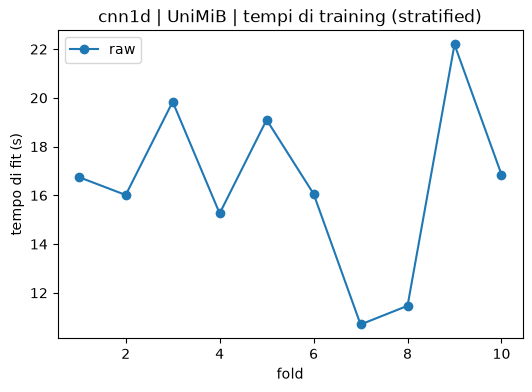

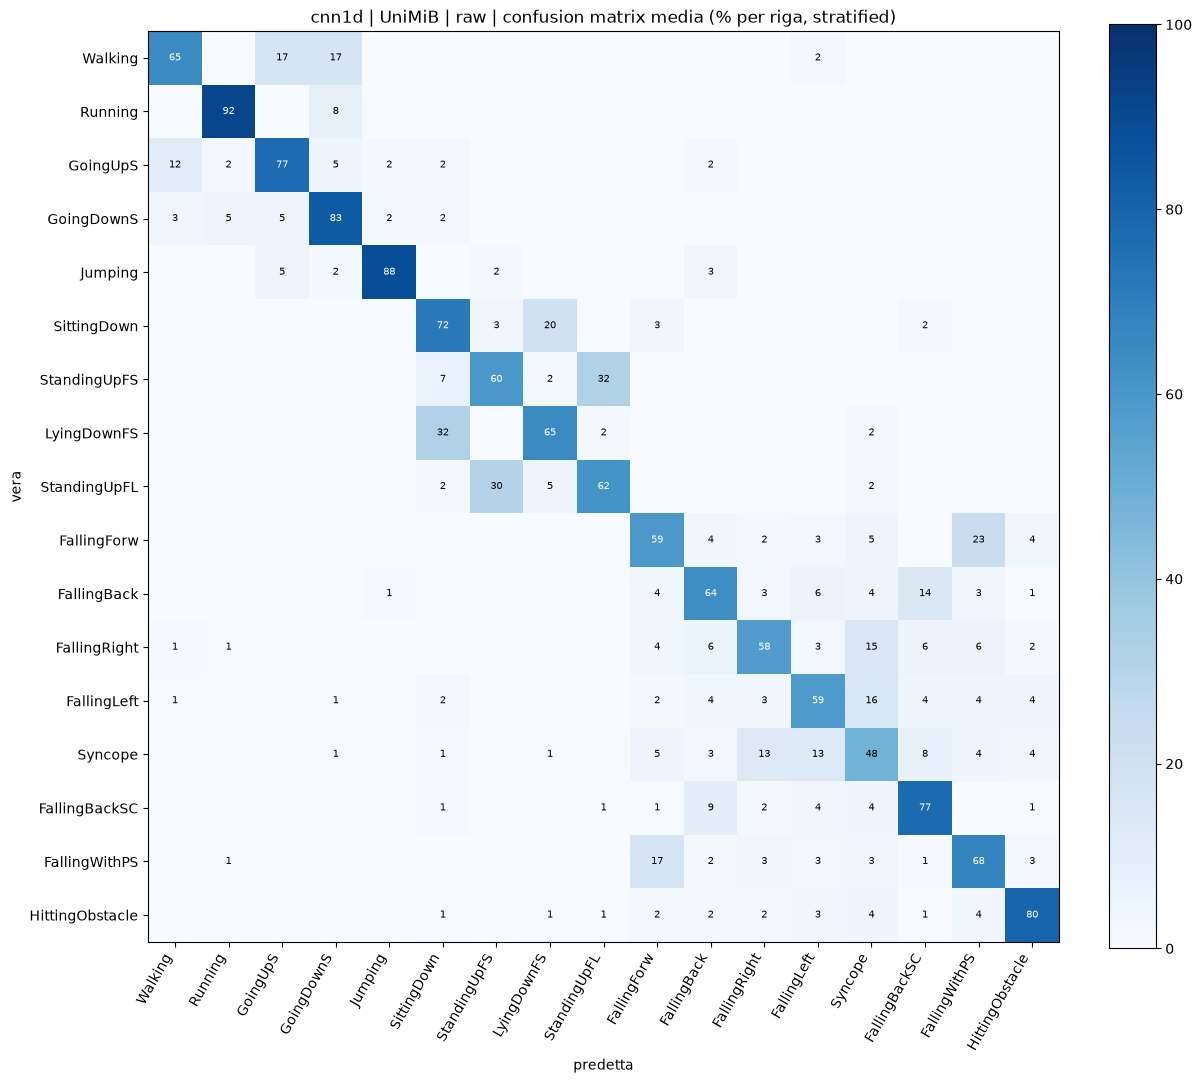

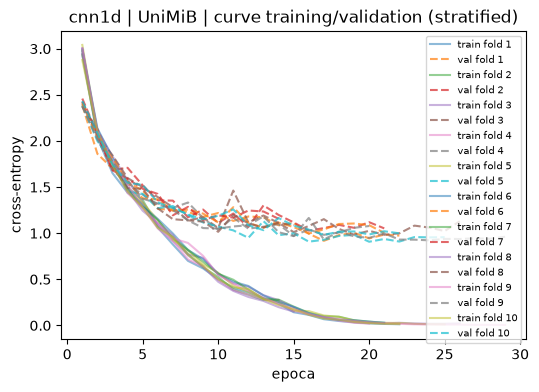

In [4]:
adv.plot_all(MODEL)